# 11 · Reranking and diversity

## The engineering question
Does a more expensive reader improve the final list, and what can it never repair?

**Learning outcomes:** measure candidate recall before reranking; compare cross-encoder ordering, document grouping, and MMR; report stage timings and held-out quality; distinguish diversity from relevance.

A bi-encoder embeds queries and documents independently. A cross-encoder jointly reads each query/document pair, making it more expressive but requiring work per candidate per request. It cannot rescue missing candidates. Grouping keeps one representative per document; maximum marginal relevance trades query similarity against redundancy among selected items. The MMR weight below is fixed at 0.7 before test scoring.

This milestone evaluates the frozen test family once with the declared pipeline, preserving development results separately. Future changes must not treat these scores as a new untouched holdout. The candidate pools are 5 and 20; final document metrics use k=5 and deduplicate documents before truncation.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("11", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


candidate_recall  recall  \
split       candidates method                                            
development 5          MMR                                 1.0     1.0   
                       cross-encoder                       1.0     1.0   
                       grouped cross-encoder               1.0     1.0   
                       hybrid                              1.0     1.0   
            20         MMR                                 1.0     1.0   
                       cross-encoder                       1.0     1.0   
                       grouped cross-encoder               1.0     1.0   
                       hybrid                              1.0     1.0   
test        5          MMR                                 1.0     1.0   
                       cross-encoder                       1.0     1.0   
                       grouped cross-encoder               1.0     1.0   
                       hybrid                              1.0     1.0   
            20         MMR                                 1.0     1.0   
                       cross-encoder                       1.0     1.0   
                       grouped cross-encoder               1.0     1.0   
                       hybrid                              1.0     1.0   

                                                   mrr      ndcg  \
split       candidates method                                      
development 5          MMR                    0.888889  0.916667   
                       cross-encoder          1.000000  1.000000   
                       grouped cross-encoder  1.000000  1.000000   
                       hybrid                 1.000000  1.000000   
            20         MMR                    0.888889  0.916667   
                       cross-encoder          1.000000  1.000000   
                       grouped cross-encoder  1.000000  1.000000   
                       hybrid                 0.916667  0.938488   
test        5          MMR                    1.000000  1.000000   
                       cross-encoder          1.000000  1.000000   
                       grouped cross-encoder  1.000000  1.000000   
                       hybrid                 1.000000  1.000000   
            20         MMR                    1.000000  1.000000   
                       cross-encoder          1.000000  1.000000   
                       grouped cross-encoder  1.000000  1.000000   
                       hybrid                 1.000000  1.000000   

                                              additional_seconds  
split       candidates method                                     
development 5          MMR                              0.017293  
                       cross-encoder                    0.019186  
                       grouped cross-encoder            0.019186  
                       hybrid                           0.000000  
            20         MMR                              0.048003  
                       cross-encoder                    0.033820  
                       grouped cross-encoder            0.033820  
                       hybrid                           0.000000  
test        5          MMR                              0.015091  
                       cross-encoder                    0.011755  
                       grouped cross-encoder            0.011755  
                       hybrid                           0.000000  
            20         MMR                              0.044437  
                       cross-encoder                    0.031204  
                       grouped cross-encoder            0.031204  
                       hybrid                           0.000000

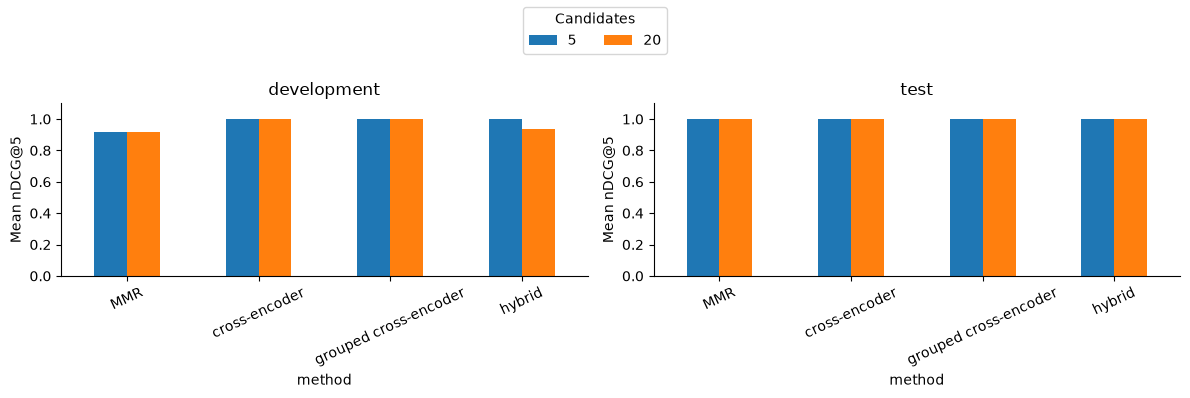

In [2]:
import time
from uuid import uuid4
from vector_masterclass.data import documents, queries
from vector_masterclass.store import VectorIndex
from vector_masterclass.chunking import chunk_document
from vector_masterclass.models import embed, rerank
from vector_masterclass.retrieval import mmr
from vector_masterclass.metrics import ranking_metrics

docs = documents(tenant="public")
index = VectorIndex("vmc_11_" + uuid4().hex[:8])
index.create()
rows, rankings = [], []
try:
    for doc in docs:
        index.upsert(chunk_document(doc), document_id=doc.id)
    for split in ["development", "test"]:
        for q in queries(split):
            for candidates in [5, 20]:
                started = time.perf_counter()
                hits = index.search(
                    q.text, tenant=q.tenant, mode="hybrid", k=candidates, candidate_k=20, exact=True
                )
                retrieval_seconds = time.perf_counter() - started
                started = time.perf_counter()
                scores = rerank(q.text, [h.chunk.text for h in hits])
                order = sorted(range(len(hits)), key=lambda i: (-float(scores[i]), hits[i].id))
                rerank_seconds = time.perf_counter() - started
                started = time.perf_counter()
                vectors = embed([h.chunk.text for h in hits])
                diverse = mmr(
                    embed([q.text], role="query")[0], vectors, k=min(5, len(hits)), weight=0.7
                )
                mmr_seconds = time.perf_counter() - started
                grouped = []
                seen = set()
                for i in order:
                    if hits[i].chunk.document_key not in seen:
                        grouped.append(i)
                        seen.add(hits[i].chunk.document_key)
                candidate_metrics = ranking_metrics(
                    [h.chunk.document_key for h in hits], q.relevance, k=candidates
                )
                for method, indices in [
                    ("hybrid", list(range(len(hits)))),
                    ("cross-encoder", order),
                    ("grouped cross-encoder", grouped),
                    ("MMR", diverse),
                ]:
                    keys = [hits[i].chunk.document_key for i in indices]
                    rows.append(
                        {
                            "split": split,
                            "query": q.id,
                            "method": method,
                            "candidates": candidates,
                            "candidate_recall": candidate_metrics["recall"],
                            "retrieval_seconds": retrieval_seconds,
                            "additional_seconds": rerank_seconds
                            if "encoder" in method
                            else mmr_seconds
                            if method == "MMR"
                            else 0,
                            "unique_documents_in_first_five_chunks": len(set(keys[:5])),
                            **ranking_metrics(keys, q.relevance, k=5),
                        }
                    )
                    rankings.append(
                        {
                            "split": split,
                            "query": q.id,
                            "method": method,
                            "candidates": candidates,
                            "first_five_chunks": keys[:5],
                        }
                    )
finally:
    index.drop()
    index.close()
results = lesson.table(pd.DataFrame(rows))
display(
    results.groupby(["split", "candidates", "method"])[
        ["candidate_recall", "recall", "mrr", "ndcg", "additional_seconds"]
    ].mean()
)
lesson.table(pd.DataFrame(rankings), "rankings")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["development", "test"]):
    frame = results[results.split.eq(split)].groupby(["method", "candidates"]).ndcg.mean().unstack()
    frame.plot.bar(ax=ax)
    ax.set(title=split, ylabel="Mean nDCG@5", ylim=(0, 1.1))
    ax.tick_params(axis="x", rotation=25)
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Candidates", loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.84))
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Compare final recall with candidate recall before blaming the reranker. Candidate starvation and reranking errors need different fixes. Grouping may leave the deduplicated document metric unchanged while improving the first five displayed chunks; this is why both diagnostics are recorded. MMR can intentionally sacrifice similarity to cover a broader set. Small corpora and label incompleteness limit ranking conclusions.

**Exercise:** find a reranking regression or, if none occurs in this run, construct a development distractor that differs only in a product identifier. Explain why cross-encoder scores are not calibrated probabilities. Choose a candidate budget using measured quality and incremental latency, then defend the choice without changing the frozen test questions.

First model use is cold; later rows benefit from loaded weights. Stage timings include Python/inference overhead and should not be read as a controlled CPU microbenchmark. [Cross-encoder model card](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2).

In [3]:
valid = results.dropna(subset=["recall", "candidate_recall"])
manifest = lesson.finish(
    {
        "both_splits": set(results.split) == {"development", "test"},
        "both_candidate_limits": set(results.candidates) == {5, 20},
        "reranking_cannot_create_candidates": bool(
            (valid.recall <= valid.candidate_recall + 1e-9).all()
        ),
        "all_methods": results.method.nunique() == 4,
    },
    observations={
        "frozen_test_evaluation": True,
        "MMR_weight": 0.7,
        "cross_encoder": "local pinned real inference",
    },
)

{
  "artifact": "artifacts/20261031T043320Z-4ff38b/11",
  "checks": {
    "both_splits": true,
    "both_candidate_limits": true,
    "reranking_cannot_create_candidates": true,
    "all_methods": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.